# Loan word classification — NEW pipeline trial (4 language pairs)

Copy of `evaluate-experiments.ipynb` adapted to run the **improved pipeline end-to-end** on a
small subset of the already-available datasets:

1. **Epitran G2P** — the `*_epitran` IPA columns are already baked into the alldata CSVs
   (produced by `make-datasets.ipynb`; verified below).
2. **Attention sequence model** (replaces the original MLP alignment network) → `DNN_logits`
3. **mmBERT** (`jhu-clsp/mmBERT-base`, masked mean pooling) → `MBERT_cos_sim`
4. **GTE** (`Alibaba-NLP/gte-multilingual-base`, [CLS] pooling) → `XLM_cos_sim`
5. **Final classifiers** (Logistic Regression + Random Forest) on the 10 core features
   + 24 script one-hot features, same protocol as the original notebook.

Pairs: Romanian-Hungarian, English-German, Finnish-Swedish, Chinese-English (alldata splits).

Requires: `transformers>=5.20` + `torch>=2.6` (for the mmBERT/GTE model types).
Results are printed/saved in-memory only — the paper's `Final_results/` files are untouched.


In [1]:
import sklearn as sk
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (precision_recall_fscore_support as score,
                             accuracy_score, f1_score, precision_score, recall_score,
                             classification_report, confusion_matrix)
import pandas as pd
import numpy as np
import os, json, random
import matplotlib.pyplot as plt
import panphon
import torch
from torch import nn
from torch import optim
from torch.utils.data import DataLoader
from transformers import AutoTokenizer, AutoModel

/home/krstff/miniconda3/envs/loanword/lib/python3.10/site-packages/panphon/featuretable.py:11: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/home/krstff/miniconda3/envs/loanword/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using {device} device")

# Subset of available language pairs (~4) for the pipeline trial
pairs = ['Romanian-Hungarian', 'English-German', 'Finnish-Swedish', 'Chinese-English']

Using cuda device


In [3]:
# Load alldata train/test splits (Epitran G2P columns are already included from make-datasets)
train_alldata = {}
test_alldata = {}

for pair in pairs:
    prefix = f'../Datasets/train_test_split/{pair}/alldata'
    train_alldata[pair] = pd.read_csv(f'{prefix}/{pair}-train_production_alldata.csv')
    test_alldata[pair] = pd.read_csv(f'{prefix}/{pair}-test_production_alldata.csv')
    for name, df in [('train', train_alldata[pair]), ('test', test_alldata[pair])]:
        for col in ['loan_word_epitran', 'original_word_epitran']:
            assert col in df.columns, f'{pair} {name} missing {col}'
        n_blank = df[col].isna().sum()
    print(f"{pair}: train={len(train_alldata[pair])} test={len(test_alldata[pair])} "
          f"blank epitran (train/test) = "
          f"{train_alldata[pair]['loan_word_epitran'].isna().sum() + train_alldata[pair]['original_word_epitran'].isna().sum()} / "
          f"{test_alldata[pair]['loan_word_epitran'].isna().sum() + test_alldata[pair]['original_word_epitran'].isna().sum()}")

Romanian-Hungarian: train=12184 test=1350 blank epitran (train/test) = 0 / 0
English-German: train=19876 test=2207 blank epitran (train/test) = 0 / 0
Finnish-Swedish: train=11462 test=1271 blank epitran (train/test) = 0 / 0
Chinese-English: train=8235 test=911 blank epitran (train/test) = 0 / 0


In [4]:
# PanPhon feature table (shared) — per-position feature vectors, NOT flattened
FT = panphon.FeatureTable()
FEAT_DIM = len(FT.word_to_vector_list('a', numeric=True)[0])
print(f"PanPhon feature dim: {FEAT_DIM}")

def get_panphon_sequences(train_set, test_set):
    # Get per-position PanPhon feature sequences for loan and original words.
    # (Empty transcriptions get a single zero position so masks always have
    # at least one valid position — keeps attention numerically safe.)
    def seqs(w):
        v = FT.word_to_vector_list(w, numeric=True)
        return v if v else [[0.0] * FEAT_DIM]
    train_set['seq_loan'] = train_set['loan_word_epitran'].apply(seqs)
    train_set['seq_orig'] = train_set['original_word_epitran'].apply(seqs)
    test_set['seq_loan'] = test_set['loan_word_epitran'].apply(seqs)
    test_set['seq_orig'] = test_set['original_word_epitran'].apply(seqs)


PanPhon feature dim: 24


In [5]:
def pad_panphon_sequences(train_set, test_set, maxlen):
    # Pad sequences to (maxlen, FEAT_DIM) and build padding masks (1 = valid).
    # maxlen is a tuple (loan_maxlen, orig_maxlen), as in the original notebook.
    # Idempotent: already-padded columns are left alone (safe to re-run the cell).
    def pad_one(seq, T_max):
        T = max(1, min(len(seq), T_max))
        mat = np.zeros((T_max, FEAT_DIM), dtype=np.float32)
        mat[:T] = np.array(seq[:T], dtype=np.float32)
        mask = np.zeros(T_max, dtype=np.float32)
        mask[:T] = 1.0
        return [mat, mask]
    def needs_padding(col):
        s = col.iloc[0]
        return not (len(s) == 2 and isinstance(s[0], np.ndarray) and s[0].ndim == 2)
    for df in (train_set, test_set):
        if needs_padding(df['seq_loan']):
            df['seq_loan'] = df['seq_loan'].apply(lambda s: pad_one(s, maxlen[0]))
        if needs_padding(df['seq_orig']):
            df['seq_orig'] = df['seq_orig'].apply(lambda s: pad_one(s, maxlen[1]))


In [6]:
def add_target_labels(train_set, test_set):
    Y_train = np.array([y for y in train_set['label_bin']])
    Y_test = np.array([y for y in test_set['label_bin']])
    return Y_train, Y_test

In [7]:
def make_train_val_idx(train_set, Y_train):
    # Index-based 80/20 stratified split so loan/orig sequences and masks stay
    # in sync (replaces the flat-array hstack split of the original notebook).
    idx = np.arange(len(train_set))
    tr, va = train_test_split(idx, test_size=0.2, random_state=1, stratify=Y_train)
    return tr, va


In [8]:
def seq_tensors(df, idx=None):
    # Build (loan, orig, loan_mask, orig_mask) tensors of shape (N, T, FEAT_DIM)
    if idx is not None:
        df = df.iloc[idx]
    loan = torch.tensor(np.stack([s[0] for s in df['seq_loan']]), dtype=torch.float32).to(device)
    orig = torch.tensor(np.stack([s[0] for s in df['seq_orig']]), dtype=torch.float32).to(device)
    lm = torch.tensor(np.stack([s[1] for s in df['seq_loan']]), dtype=torch.float32).to(device)
    om = torch.tensor(np.stack([s[1] for s in df['seq_orig']]), dtype=torch.float32).to(device)
    return loan, orig, lm, om

def get_logits(model, df):
    # One raw logit per row — same output convention as the original DNN logits.
    model.eval()
    with torch.no_grad():
        logits = model(*seq_tensors(df))[1]
    return logits.detach().cpu().numpy()


In [9]:
class AttentionPairModel(nn.Module):
    """Sequence-aware loanword classifier with learned phoneme alignment.

    Input: per-position PanPhon feature sequences of the loan word and the original
    word, plus padding masks (1 = valid position).

    Architecture:
        loan (B,T1,F) --Linear--> (B,T1,H)
        orig (B,T2,F) --Linear--> (B,T2,H)
        loan positions cross-attend to orig positions (and vice versa)
        masked-mean pooling of raw + aligned reps -> concat (4H) -> MLP -> logit

    The cross-attention weights are the learned alignment between the two words;
    they are stored in `self.last_alignment` for inspection/visualization.

    forward returns (sigmoid_prob, raw_logits, alignment) — index [1] is the raw
    logit, same convention as the original NeuralNetwork.
    """

    def __init__(self, feat_dim=24, hidden=64, heads=4, mlp_hidden=128, dropout=0.3):
        super(AttentionPairModel, self).__init__()
        self.loan_emb = nn.Linear(feat_dim, hidden)
        self.orig_emb = nn.Linear(feat_dim, hidden)
        self.attn_loan2orig = nn.MultiheadAttention(hidden, heads, batch_first=True, dropout=dropout)
        self.attn_orig2loan = nn.MultiheadAttention(hidden, heads, batch_first=True, dropout=dropout)
        self.classifier = nn.Sequential(
            nn.Linear(4 * hidden, mlp_hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(mlp_hidden, 1),
        )
        self.last_alignment = None

    @staticmethod
    def _masked_mean(x, mask):
        # x: (B,T,H), mask: (B,T) with 1 for valid positions
        m = mask.unsqueeze(-1).float()
        return (x * m).sum(1) / m.sum(1).clamp(min=1.0)

    def forward(self, loan, orig, loan_mask, orig_mask):
        l = self.loan_emb(loan)
        o = self.orig_emb(orig)
        l_kpm = ~loan_mask.bool()
        o_kpm = ~orig_mask.bool()
        l_att, w_l2o = self.attn_loan2orig(l, o, o, key_padding_mask=o_kpm,
                                            need_weights=True, average_attn_weights=True)
        o_att, w_o2l = self.attn_orig2loan(o, l, l, key_padding_mask=l_kpm,
                                           need_weights=True, average_attn_weights=True)
        self.last_alignment = (w_l2o, w_o2l)  # (B,T1,T2) and (B,T2,T1)
        x = torch.cat([self._masked_mean(l, loan_mask),
                       self._masked_mean(o, orig_mask),
                       self._masked_mean(l_att, loan_mask),
                       self._masked_mean(o_att, orig_mask)], dim=1)
        logits = self.classifier(x).squeeze(-1)
        return torch.sigmoid(logits), logits, self.last_alignment

    def fit(self, loan_tr, orig_tr, lm_tr, om_tr, y_tr,
            loan_val, orig_val, lm_val, om_val, y_val,
            n_epochs=100, batch_size=256, lr=0.001, weight_decay=1e-4,
            early_stop_patience=15, verbose_every=5):
        """Mini-batch training with early stopping on validation loss."""
        criterion = nn.BCEWithLogitsLoss()
        optimizer = optim.Adam(self.parameters(), lr=lr, weight_decay=weight_decay)
        n = len(y_tr)
        best_val, best_state, bad_epochs = float('inf'), None, 0
        history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

        for epoch in range(n_epochs):
            self.train()
            perm = torch.randperm(n, device=loan_tr.device)
            epoch_loss, correct = 0.0, 0
            for i in range(0, n, batch_size):
                idx = perm[i:i + batch_size]
                logits = self(loan_tr[idx], orig_tr[idx], lm_tr[idx], om_tr[idx])[1]
                loss = criterion(logits, y_tr[idx])
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
                epoch_loss += loss.item() * len(idx)
                correct += int(((logits >= 0) == (y_tr[idx] >= 0.5)).sum())

            self.eval()
            with torch.no_grad():
                vlogits = self(loan_val, orig_val, lm_val, om_val)[1]
                vloss = criterion(vlogits, y_val).item()
                vacc = float(((vlogits >= 0) == (y_val >= 0.5)).float().mean())

            tloss = epoch_loss / n
            tacc = correct / n
            history['train_loss'].append(tloss)
            history['val_loss'].append(vloss)
            history['train_acc'].append(tacc)
            history['val_acc'].append(vacc)

            if epoch % verbose_every == 0 or epoch == n_epochs - 1:
                print(f"epoch {epoch:3d} | train loss {tloss:.4f} acc {tacc:.3f} | "
                      f"val loss {vloss:.4f} acc {vacc:.3f}")

            if vloss < best_val - 1e-4:
                best_val = vloss
                best_state = {k: v.detach().clone() for k, v in self.state_dict().items()}
                bad_epochs = 0
            else:
                bad_epochs += 1
                if bad_epochs >= early_stop_patience:
                    print(f"early stopping at epoch {epoch} (best val loss {best_val:.4f})")
                    break

        if best_state is not None:
            self.load_state_dict(best_state)
        self.eval()
        return history

    @staticmethod
    def plot_history(history):
        epochs = range(1, len(history['train_loss']) + 1)
        plt.plot(epochs, history['train_loss'], label='Train loss')
        plt.plot(epochs, history['val_loss'], label='Val loss')
        plt.title('Training and validation loss')
        plt.legend()
        plt.show()
        plt.figure()
        plt.plot(epochs, history['train_acc'], label='Train acc')
        plt.plot(epochs, history['val_acc'], label='Val acc')
        plt.title('Training and validation accuracy')
        plt.legend()
        plt.show()


In [10]:
# Semantic similarity models (replacing the paper's MBERT and XLM-100)
PRE_TRAINED_bert_MODEL = 'jhu-clsp/mmBERT-base'              # ModernBERT architecture
PRE_TRAINED_xlm_MODEL  = 'Alibaba-NLP/gte-multilingual-base' # GTE architecture
MAXTOKENS = 128
BS = 256

# Preload (pre-download) both models
mmbert_model = AutoModel.from_pretrained(PRE_TRAINED_bert_MODEL).to(device)
gte_model = AutoModel.from_pretrained(PRE_TRAINED_xlm_MODEL).to(device)
mmbert_model.eval()
gte_model.eval()

Loading weights: 100%|██████████| 134/134 [00:00<00:00, 7416.20it/s]
[transformers] ModernBertModel LOAD REPORT from: jhu-clsp/mmBERT-base
Key               | Status     |  | 
------------------+------------+--+-
head.dense.weight | UNEXPECTED |  | 
decoder.weight    | UNEXPECTED |  | 
decoder.bias      | UNEXPECTED |  | 
head.norm.weight  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Loading weights: 100%|██████████| 136/136 [00:00<00:00, 1465.61it/s]
[transformers] GteModel LOAD REPORT from: Alibaba-NLP/gte-multilingual-base
Key               | Status     |  | 
------------------+------------+--+-
classifier.weight | UNEXPECTED |  | 
classifier.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


GteModel(
  (embeddings): GteEmbeddings(
    (word_embeddings): Embedding(250048, 768, padding_idx=1)
    (token_type_embeddings): Embedding(1, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (rotary_emb): GteRotaryEmbedding()
  (layers): ModuleList(
    (0-11): 12 x GteLayer(
      (post_attention_layernorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
      (post_attention_dropout): Dropout(p=0.1, inplace=False)
      (post_mlp_dropout): Dropout(p=0.1, inplace=False)
      (mlp): GteMLP(
        (gate_proj): Linear(in_features=768, out_features=3072, bias=False)
        (up_proj): Linear(in_features=768, out_features=3072, bias=False)
        (down_proj): Linear(in_features=3072, out_features=768, bias=True)
        (act_fn): GELUActivation()
        (dropout): Dropout(p=0.1, inplace=False)
      )
      (self_attn): GteAttention(
        (q_proj): Linear(in_features=768, ou

In [11]:
# Overriding the Dataset class required for the use of PyTorch's data loader classes.
class MyDataset(torch.utils.data.Dataset):
    def __init__(self, l1_encodings, l2_encodings):
        self.l1_encodings = l1_encodings
        self.l2_encodings = l2_encodings

    def __getitem__(self, idx):
        item = {('l1_' + key): torch.tensor(val[idx]) for key, val in self.l1_encodings.items()}
        item2 = {('l2_' + key): torch.tensor(val[idx]) for key, val in self.l2_encodings.items()}
        item.update(item2)
        # item['labels'] = torch.tensor(self.labels[idx])
        return item

    def __len__(self):
        return len(self.l1_encodings['attention_mask'])

In [12]:
def get_mbert_cos_sims(l1_data, l2_data):
    """Masked mean-pooled cosine similarity with jhu-clsp/mmBERT-base (ModernBERT).
    NOTE: [CLS] pooling is degenerate for this MLM checkpoint (all sims ~0.999),
    so we use attention-masked mean pooling instead."""
    with torch.no_grad():
        tokenizer = AutoTokenizer.from_pretrained(PRE_TRAINED_bert_MODEL)
        tokenizer.model_max_length = MAXTOKENS
        l1_encodings = tokenizer(list(l1_data), truncation=True, padding=True, max_length=MAXTOKENS, return_tensors="pt")
        l2_encodings = tokenizer(list(l2_data), truncation=True, padding=True, max_length=MAXTOKENS, return_tensors="pt")

        dataset = MyDataset(l1_encodings, l2_encodings)

        data_loader = DataLoader(dataset, batch_size=BS, shuffle=False)  # shuffle False for reproducibility

        base_model = AutoModel.from_pretrained(PRE_TRAINED_bert_MODEL).to(device)
        base_model.eval()
        cos_s = torch.nn.CosineSimilarity()

        def pool(h, m):
            h = h * m.unsqueeze(-1).float()
            return torch.nn.functional.normalize(h.sum(1) / m.sum(1).unsqueeze(-1).float(), dim=1)

        sim_lst = []

        #loop through dataset
        for step, batch in enumerate(data_loader):
            l1_h = base_model(batch['l1_input_ids'].to(device),
                              attention_mask=batch['l1_attention_mask'].to(device),
                              return_dict=True).last_hidden_state
            l2_h = base_model(batch['l2_input_ids'].to(device),
                              attention_mask=batch['l2_attention_mask'].to(device),
                              return_dict=True).last_hidden_state
            l1_vector = pool(l1_h, batch['l1_attention_mask'].to(device))
            l2_vector = pool(l2_h, batch['l2_attention_mask'].to(device))
            sims = cos_s(l1_vector, l2_vector).data.cpu().numpy()
            sim_lst.extend(list(sims))
            if (step * BS) % 100 < BS:
                print("Got {}".format(len(sim_lst)))
        print()

    return sim_lst

In [13]:
def get_xlm_cos_sims(l1_data, l2_data):
    """[CLS] cosine similarity with Alibaba-NLP/gte-multilingual-base (GTE)."""
    with torch.no_grad():
        tokenizer = AutoTokenizer.from_pretrained(PRE_TRAINED_xlm_MODEL)
        tokenizer.model_max_length = MAXTOKENS
        l1_encodings = tokenizer(list(l1_data), truncation=True, padding=True, max_length=MAXTOKENS, return_tensors="pt")
        l2_encodings = tokenizer(list(l2_data), truncation=True, padding=True, max_length=MAXTOKENS, return_tensors="pt")

        dataset = MyDataset(l1_encodings, l2_encodings)

        data_loader = DataLoader(dataset, batch_size=BS, shuffle=False)  # shuffle False for reproducibility

        base_model = AutoModel.from_pretrained(PRE_TRAINED_xlm_MODEL).to(device)
        base_model.eval()
        cos_s = torch.nn.CosineSimilarity()

        sim_lst = []

        #loop through dataset
        for step, batch in enumerate(data_loader):
            l1_vector = base_model(batch['l1_input_ids'].to(device),
                                          attention_mask=batch['l1_attention_mask'].to(device),
                                          return_dict=True).last_hidden_state[:, 0, :]
            l2_vector = base_model(batch['l2_input_ids'].to(device),
                                          attention_mask=batch['l2_attention_mask'].to(device),
                                          return_dict=True).last_hidden_state[:, 0, :]
            sims = cos_s(l1_vector, l2_vector).data.cpu().numpy()
            sim_lst.extend(list(sims))
            if (step * BS) % 100 < BS:
                print("Got {}".format(len(sim_lst)))
        print()

    return sim_lst


Romanian-Hungarian
epoch   0 | train loss 0.3957 acc 0.861 | val loss 0.3384 acc 0.892
epoch  10 | train loss 0.2636 acc 0.892 | val loss 0.2482 acc 0.889
epoch  20 | train loss 0.1971 acc 0.909 | val loss 0.1833 acc 0.914
epoch  30 | train loss 0.1556 acc 0.930 | val loss 0.2041 acc 0.906
epoch  40 | train loss 0.1438 acc 0.936 | val loss 0.1795 acc 0.919
epoch  50 | train loss 0.1330 acc 0.941 | val loss 0.1501 acc 0.935
epoch  60 | train loss 0.1323 acc 0.942 | val loss 0.1566 acc 0.933
epoch  70 | train loss 0.1246 acc 0.948 | val loss 0.1468 acc 0.935
epoch  80 | train loss 0.1212 acc 0.946 | val loss 0.1465 acc 0.938
early stopping at epoch 88 (best val loss 0.1452)


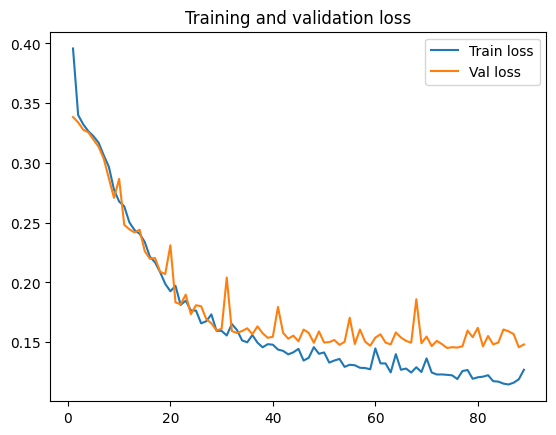

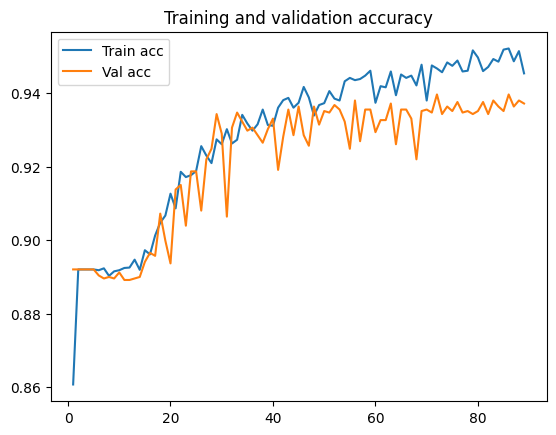

Loading weights: 100%|██████████| 134/134 [00:00<00:00, 5952.58it/s]
[transformers] ModernBertModel LOAD REPORT from: jhu-clsp/mmBERT-base
Key               | Status     |  | 
------------------+------------+--+-
head.dense.weight | UNEXPECTED |  | 
decoder.weight    | UNEXPECTED |  | 
decoder.bias      | UNEXPECTED |  | 
head.norm.weight  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
/tmp/ipykernel_3036103/1127116239.py:8: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  item = {('l1_' + key): torch.tensor(val[idx]) for key, val in self.l1_encodings.items()}
/tmp/ipykernel_3036103/1127116239.py:9: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(Tr

Got 256
Got 512
Got 768
Got 1024
Got 1280
Got 1536
Got 1792
Got 2048
Got 2304
Got 2560
Got 2816
Got 3072
Got 3328
Got 3584
Got 3840
Got 4096
Got 4352
Got 4608
Got 4864
Got 5120
Got 5376
Got 5632
Got 5888
Got 6144
Got 6400
Got 6656
Got 6912
Got 7168
Got 7424
Got 7680
Got 7936
Got 8192
Got 8448
Got 8704
Got 8960
Got 9216
Got 9472
Got 9728
Got 9984
Got 10240
Got 10496
Got 10752
Got 11008
Got 11264
Got 11520
Got 11776
Got 12032
Got 12184



Loading weights: 100%|██████████| 134/134 [00:00<00:00, 7566.66it/s]
[transformers] ModernBertModel LOAD REPORT from: jhu-clsp/mmBERT-base
Key               | Status     |  | 
------------------+------------+--+-
head.dense.weight | UNEXPECTED |  | 
decoder.weight    | UNEXPECTED |  | 
decoder.bias      | UNEXPECTED |  | 
head.norm.weight  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Got 256
Got 512
Got 768
Got 1024
Got 1280
Got 1350



Loading weights: 100%|██████████| 136/136 [00:00<00:00, 1397.34it/s]
[transformers] GteModel LOAD REPORT from: Alibaba-NLP/gte-multilingual-base
Key               | Status     |  | 
------------------+------------+--+-
classifier.weight | UNEXPECTED |  | 
classifier.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Got 256
Got 512
Got 768
Got 1024
Got 1280
Got 1536
Got 1792
Got 2048
Got 2304
Got 2560
Got 2816
Got 3072
Got 3328
Got 3584
Got 3840
Got 4096
Got 4352
Got 4608
Got 4864
Got 5120
Got 5376
Got 5632
Got 5888
Got 6144
Got 6400
Got 6656
Got 6912
Got 7168
Got 7424
Got 7680
Got 7936
Got 8192
Got 8448
Got 8704
Got 8960
Got 9216
Got 9472
Got 9728
Got 9984
Got 10240
Got 10496
Got 10752
Got 11008
Got 11264
Got 11520
Got 11776
Got 12032
Got 12184



Loading weights: 100%|██████████| 136/136 [00:00<00:00, 1434.57it/s]
[transformers] GteModel LOAD REPORT from: Alibaba-NLP/gte-multilingual-base
Key               | Status     |  | 
------------------+------------+--+-
classifier.weight | UNEXPECTED |  | 
classifier.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Got 256
Got 512
Got 768
Got 1024
Got 1280
Got 1350


English-German
epoch   0 | train loss 0.4214 acc 0.851 | val loss 0.3888 acc 0.867
epoch  10 | train loss 0.2435 acc 0.891 | val loss 0.2004 acc 0.893
epoch  20 | train loss 0.1745 acc 0.924 | val loss 0.1416 acc 0.939
epoch  30 | train loss 0.1445 acc 0.938 | val loss 0.1209 acc 0.950
epoch  40 | train loss 0.1328 acc 0.946 | val loss 0.1188 acc 0.950
epoch  50 | train loss 0.1208 acc 0.951 | val loss 0.1181 acc 0.947
epoch  60 | train loss 0.1148 acc 0.952 | val loss 0.1043 acc 0.961
epoch  70 | train loss 0.1089 acc 0.959 | val loss 0.1031 acc 0.961
epoch  80 | train loss 0.1050 acc 0.959 | val loss 0.0984 acc 0.963
epoch  90 | train loss 0.0985 acc 0.962 | val loss 0.1093 acc 0.954
early stopping at epoch 98 (best val loss 0.0942)


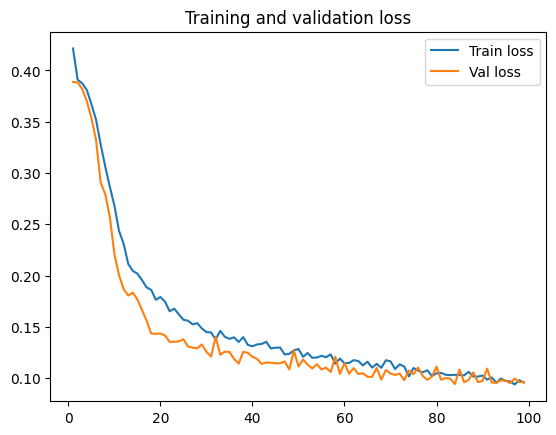

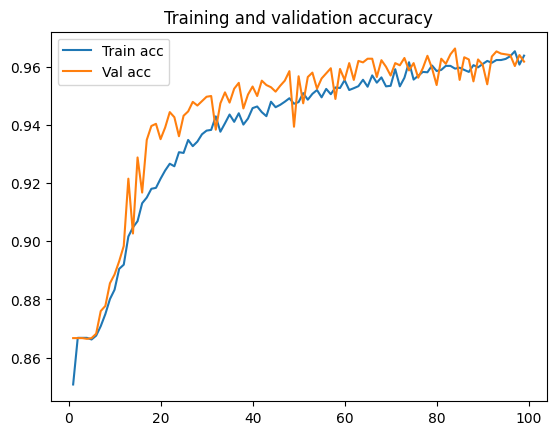

Loading weights: 100%|██████████| 134/134 [00:00<00:00, 3911.43it/s]
[transformers] ModernBertModel LOAD REPORT from: jhu-clsp/mmBERT-base
Key               | Status     |  | 
------------------+------------+--+-
head.dense.weight | UNEXPECTED |  | 
decoder.weight    | UNEXPECTED |  | 
decoder.bias      | UNEXPECTED |  | 
head.norm.weight  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
/tmp/ipykernel_3036103/1127116239.py:8: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  item = {('l1_' + key): torch.tensor(val[idx]) for key, val in self.l1_encodings.items()}
/tmp/ipykernel_3036103/1127116239.py:9: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(Tr

Got 256
Got 512
Got 768
Got 1024
Got 1280
Got 1536
Got 1792
Got 2048
Got 2304
Got 2560
Got 2816
Got 3072
Got 3328
Got 3584
Got 3840
Got 4096
Got 4352
Got 4608
Got 4864
Got 5120
Got 5376
Got 5632
Got 5888
Got 6144
Got 6400
Got 6656
Got 6912
Got 7168
Got 7424
Got 7680
Got 7936
Got 8192
Got 8448
Got 8704
Got 8960
Got 9216
Got 9472
Got 9728
Got 9984
Got 10240
Got 10496
Got 10752
Got 11008
Got 11264
Got 11520
Got 11776
Got 12032
Got 12288
Got 12544
Got 12800
Got 13056
Got 13312
Got 13568
Got 13824
Got 14080
Got 14336
Got 14592
Got 14848
Got 15104
Got 15360
Got 15616
Got 15872
Got 16128
Got 16384
Got 16640
Got 16896
Got 17152
Got 17408
Got 17664
Got 17920
Got 18176
Got 18432
Got 18688
Got 18944
Got 19200
Got 19456
Got 19712
Got 19876



Loading weights: 100%|██████████| 134/134 [00:00<00:00, 6663.23it/s]
[transformers] ModernBertModel LOAD REPORT from: jhu-clsp/mmBERT-base
Key               | Status     |  | 
------------------+------------+--+-
head.dense.weight | UNEXPECTED |  | 
decoder.weight    | UNEXPECTED |  | 
decoder.bias      | UNEXPECTED |  | 
head.norm.weight  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Got 256
Got 512
Got 768
Got 1024
Got 1280
Got 1536
Got 1792
Got 2048
Got 2207



Loading weights: 100%|██████████| 136/136 [00:00<00:00, 1389.03it/s]
[transformers] GteModel LOAD REPORT from: Alibaba-NLP/gte-multilingual-base
Key               | Status     |  | 
------------------+------------+--+-
classifier.weight | UNEXPECTED |  | 
classifier.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Got 256
Got 512
Got 768
Got 1024
Got 1280
Got 1536
Got 1792
Got 2048
Got 2304
Got 2560
Got 2816
Got 3072
Got 3328
Got 3584
Got 3840
Got 4096
Got 4352
Got 4608
Got 4864
Got 5120
Got 5376
Got 5632
Got 5888
Got 6144
Got 6400
Got 6656
Got 6912
Got 7168
Got 7424
Got 7680
Got 7936
Got 8192
Got 8448
Got 8704
Got 8960
Got 9216
Got 9472
Got 9728
Got 9984
Got 10240
Got 10496
Got 10752
Got 11008
Got 11264
Got 11520
Got 11776
Got 12032
Got 12288
Got 12544
Got 12800
Got 13056
Got 13312
Got 13568
Got 13824
Got 14080
Got 14336
Got 14592
Got 14848
Got 15104
Got 15360
Got 15616
Got 15872
Got 16128
Got 16384
Got 16640
Got 16896
Got 17152
Got 17408
Got 17664
Got 17920
Got 18176
Got 18432
Got 18688
Got 18944
Got 19200
Got 19456
Got 19712
Got 19876



Loading weights: 100%|██████████| 136/136 [00:00<00:00, 1893.79it/s]
[transformers] GteModel LOAD REPORT from: Alibaba-NLP/gte-multilingual-base
Key               | Status     |  | 
------------------+------------+--+-
classifier.weight | UNEXPECTED |  | 
classifier.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Got 256
Got 512
Got 768
Got 1024
Got 1280
Got 1536
Got 1792
Got 2048
Got 2207


Finnish-Swedish
epoch   0 | train loss 0.3798 acc 0.870 | val loss 0.3196 acc 0.902
epoch  10 | train loss 0.2560 acc 0.903 | val loss 0.2678 acc 0.903
epoch  20 | train loss 0.1943 acc 0.918 | val loss 0.1841 acc 0.919
epoch  30 | train loss 0.1630 acc 0.926 | val loss 0.1716 acc 0.925
epoch  40 | train loss 0.1511 acc 0.931 | val loss 0.1642 acc 0.928
epoch  50 | train loss 0.1435 acc 0.935 | val loss 0.1616 acc 0.928
epoch  60 | train loss 0.1348 acc 0.938 | val loss 0.1571 acc 0.930
epoch  70 | train loss 0.1279 acc 0.942 | val loss 0.1476 acc 0.942
epoch  80 | train loss 0.1275 acc 0.945 | val loss 0.1488 acc 0.938
epoch  90 | train loss 0.1170 acc 0.947 | val loss 0.1547 acc 0.939
epoch  99 | train loss 0.1153 acc 0.952 | val loss 0.1559 acc 0.932


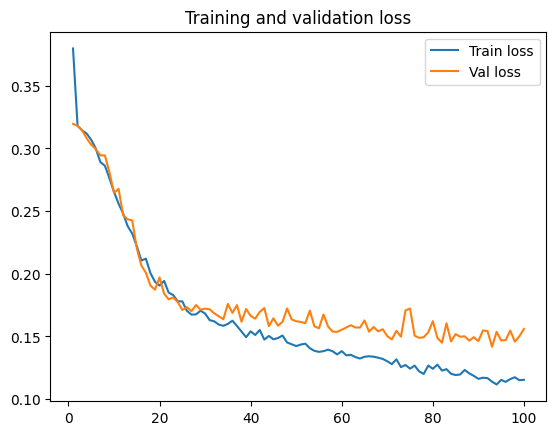

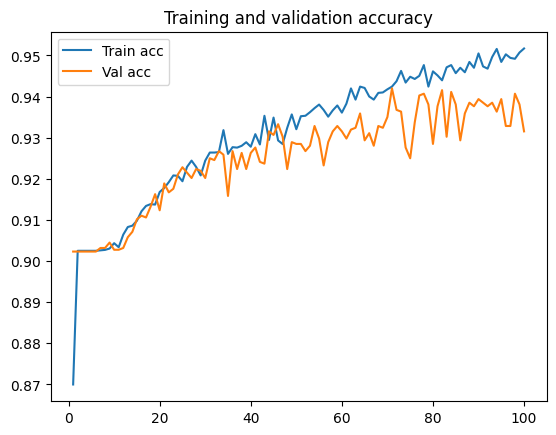

Loading weights: 100%|██████████| 134/134 [00:00<00:00, 5737.94it/s]
[transformers] ModernBertModel LOAD REPORT from: jhu-clsp/mmBERT-base
Key               | Status     |  | 
------------------+------------+--+-
head.dense.weight | UNEXPECTED |  | 
decoder.weight    | UNEXPECTED |  | 
decoder.bias      | UNEXPECTED |  | 
head.norm.weight  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
/tmp/ipykernel_3036103/1127116239.py:8: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  item = {('l1_' + key): torch.tensor(val[idx]) for key, val in self.l1_encodings.items()}
/tmp/ipykernel_3036103/1127116239.py:9: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(Tr

Got 256
Got 512
Got 768
Got 1024
Got 1280
Got 1536
Got 1792
Got 2048
Got 2304
Got 2560
Got 2816
Got 3072
Got 3328
Got 3584
Got 3840
Got 4096
Got 4352
Got 4608
Got 4864
Got 5120
Got 5376
Got 5632
Got 5888
Got 6144
Got 6400
Got 6656
Got 6912
Got 7168
Got 7424
Got 7680
Got 7936
Got 8192
Got 8448
Got 8704
Got 8960
Got 9216
Got 9472
Got 9728
Got 9984
Got 10240
Got 10496
Got 10752
Got 11008
Got 11264
Got 11462



Loading weights: 100%|██████████| 134/134 [00:00<00:00, 6951.25it/s]
[transformers] ModernBertModel LOAD REPORT from: jhu-clsp/mmBERT-base
Key               | Status     |  | 
------------------+------------+--+-
head.dense.weight | UNEXPECTED |  | 
decoder.weight    | UNEXPECTED |  | 
decoder.bias      | UNEXPECTED |  | 
head.norm.weight  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Got 256
Got 512
Got 768
Got 1024
Got 1271



Loading weights: 100%|██████████| 136/136 [00:00<00:00, 1363.72it/s]
[transformers] GteModel LOAD REPORT from: Alibaba-NLP/gte-multilingual-base
Key               | Status     |  | 
------------------+------------+--+-
classifier.weight | UNEXPECTED |  | 
classifier.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Got 256
Got 512
Got 768
Got 1024
Got 1280
Got 1536
Got 1792
Got 2048
Got 2304
Got 2560
Got 2816
Got 3072
Got 3328
Got 3584
Got 3840
Got 4096
Got 4352
Got 4608
Got 4864
Got 5120
Got 5376
Got 5632
Got 5888
Got 6144
Got 6400
Got 6656
Got 6912
Got 7168
Got 7424
Got 7680
Got 7936
Got 8192
Got 8448
Got 8704
Got 8960
Got 9216
Got 9472
Got 9728
Got 9984
Got 10240
Got 10496
Got 10752
Got 11008
Got 11264
Got 11462



Loading weights: 100%|██████████| 136/136 [00:00<00:00, 1428.10it/s]
[transformers] GteModel LOAD REPORT from: Alibaba-NLP/gte-multilingual-base
Key               | Status     |  | 
------------------+------------+--+-
classifier.weight | UNEXPECTED |  | 
classifier.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Got 256
Got 512
Got 768
Got 1024
Got 1271


Chinese-English
epoch   0 | train loss 0.4105 acc 0.851 | val loss 0.3369 acc 0.895
epoch  10 | train loss 0.3024 acc 0.895 | val loss 0.3071 acc 0.895
epoch  20 | train loss 0.2517 acc 0.905 | val loss 0.2577 acc 0.903
epoch  30 | train loss 0.2174 acc 0.918 | val loss 0.2186 acc 0.916
epoch  40 | train loss 0.1907 acc 0.927 | val loss 0.2096 acc 0.922
epoch  50 | train loss 0.1743 acc 0.932 | val loss 0.1995 acc 0.922
epoch  60 | train loss 0.1665 acc 0.934 | val loss 0.2089 acc 0.922
epoch  70 | train loss 0.1588 acc 0.936 | val loss 0.2036 acc 0.925
early stopping at epoch 70 (best val loss 0.1951)


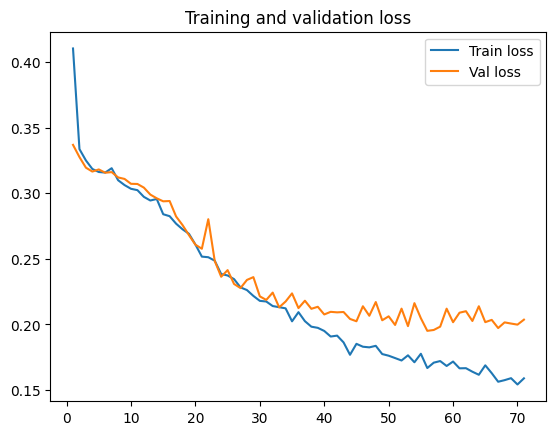

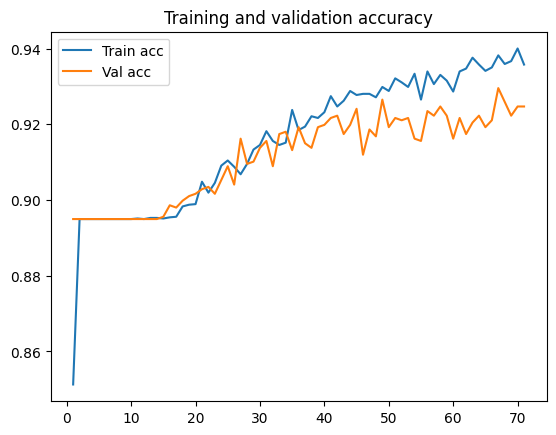

Loading weights: 100%|██████████| 134/134 [00:00<00:00, 4723.79it/s]
[transformers] ModernBertModel LOAD REPORT from: jhu-clsp/mmBERT-base
Key               | Status     |  | 
------------------+------------+--+-
head.dense.weight | UNEXPECTED |  | 
decoder.weight    | UNEXPECTED |  | 
decoder.bias      | UNEXPECTED |  | 
head.norm.weight  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
/tmp/ipykernel_3036103/1127116239.py:8: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  item = {('l1_' + key): torch.tensor(val[idx]) for key, val in self.l1_encodings.items()}
/tmp/ipykernel_3036103/1127116239.py:9: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(Tr

Got 256
Got 512
Got 768
Got 1024
Got 1280
Got 1536
Got 1792
Got 2048
Got 2304
Got 2560
Got 2816
Got 3072
Got 3328
Got 3584
Got 3840
Got 4096
Got 4352
Got 4608
Got 4864
Got 5120
Got 5376
Got 5632
Got 5888
Got 6144
Got 6400
Got 6656
Got 6912
Got 7168
Got 7424
Got 7680
Got 7936
Got 8192
Got 8235



Loading weights: 100%|██████████| 134/134 [00:00<00:00, 3644.05it/s]
[transformers] ModernBertModel LOAD REPORT from: jhu-clsp/mmBERT-base
Key               | Status     |  | 
------------------+------------+--+-
head.dense.weight | UNEXPECTED |  | 
decoder.weight    | UNEXPECTED |  | 
decoder.bias      | UNEXPECTED |  | 
head.norm.weight  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Got 256
Got 512
Got 768
Got 911



Loading weights: 100%|██████████| 136/136 [00:00<00:00, 1574.39it/s]
[transformers] GteModel LOAD REPORT from: Alibaba-NLP/gte-multilingual-base
Key               | Status     |  | 
------------------+------------+--+-
classifier.weight | UNEXPECTED |  | 
classifier.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Got 256
Got 512
Got 768
Got 1024
Got 1280
Got 1536
Got 1792
Got 2048
Got 2304
Got 2560
Got 2816
Got 3072
Got 3328
Got 3584
Got 3840
Got 4096
Got 4352
Got 4608
Got 4864
Got 5120
Got 5376
Got 5632
Got 5888
Got 6144
Got 6400
Got 6656
Got 6912
Got 7168
Got 7424
Got 7680
Got 7936
Got 8192
Got 8235



Loading weights: 100%|██████████| 136/136 [00:00<00:00, 1267.67it/s]
[transformers] GteModel LOAD REPORT from: Alibaba-NLP/gte-multilingual-base
Key               | Status     |  | 
------------------+------------+--+-
classifier.weight | UNEXPECTED |  | 
classifier.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Got 256
Got 512
Got 768
Got 911



In [14]:
# ---- Per-pair pipeline: attention DNN -> mmBERT -> GTE ----
for pair in pairs:
    print(f"\n{'='*70}\n{pair}\n{'='*70}")
    train_df = train_alldata[pair]
    test_df = test_alldata[pair]

    # 1) PanPhon sequences + attention model -> DNN_logits
    get_panphon_sequences(train_df, test_df)
    alldata_maxlen = (max(max(len(s) for s in train_df['seq_loan']), max(len(s) for s in test_df['seq_loan'])),
                      max(max(len(s) for s in train_df['seq_orig']), max(len(s) for s in test_df['seq_orig'])))
    pad_panphon_sequences(train_df, test_df, alldata_maxlen)
    Y_train, Y_test = add_target_labels(train_df, test_df)
    idx_tr, idx_va = make_train_val_idx(train_df, Y_train)
    loan_tr, orig_tr, lm_tr, om_tr = seq_tensors(train_df, idx_tr)
    loan_va, orig_va, lm_va, om_va = seq_tensors(train_df, idx_va)
    y_tr = torch.tensor(train_df['label_bin'].values[idx_tr], dtype=torch.float32).to(device)
    y_va = torch.tensor(train_df['label_bin'].values[idx_va], dtype=torch.float32).to(device)

    torch.manual_seed(666); np.random.seed(666)
    model = AttentionPairModel(feat_dim=FEAT_DIM, hidden=64, heads=4, mlp_hidden=128, dropout=0.3).to(device)
    history = model.fit(loan_tr, orig_tr, lm_tr, om_tr, y_tr,
                        loan_va, orig_va, lm_va, om_va, y_va,
                        n_epochs=100, batch_size=256, lr=0.001,
                        weight_decay=1e-4, early_stop_patience=15, verbose_every=10)
    AttentionPairModel.plot_history(history)

    train_df['DNN_logits'] = get_logits(model, train_df)
    test_df['DNN_logits'] = get_logits(model, test_df)
    train_df.drop(['seq_loan', 'seq_orig'], axis=1, inplace=True)
    test_df.drop(['seq_loan', 'seq_orig'], axis=1, inplace=True)

    # 2) mmBERT -> MBERT_cos_sim,  3) GTE -> XLM_cos_sim
    train_df['MBERT_cos_sim'] = get_mbert_cos_sims(train_df['loan_word'], train_df['original_word'])
    test_df['MBERT_cos_sim'] = get_mbert_cos_sims(test_df['loan_word'], test_df['original_word'])
    train_df['XLM_cos_sim'] = get_xlm_cos_sims(train_df['loan_word'], train_df['original_word'])
    test_df['XLM_cos_sim'] = get_xlm_cos_sims(test_df['loan_word'], test_df['original_word'])

In [15]:
# Script one-hot features (same as original notebook, alldata only)
unicode_list = ["Latin", "Greek", "Cyrillic", "Arabic", "Devanagari", "Bengali", "Gurmukhi",
                   "Tamil", "Telugu", "Malayalam", "Myanmar", "Chinese"]
# one-hot per script, aligned with the column names (original notebook had a
# sorted-order vs original-order mismatch; this version is consistent)
unicode_map = {w: [int(u == w) for u in unicode_list] for w in unicode_list}

for pair in pairs:
    for df in (train_alldata[pair], test_alldata[pair]):
        loan_oh = pd.DataFrame(df['loan_unicode'].map(unicode_map).tolist(),
                               columns=[f'loan_unicode_{w}' for w in unicode_list])
        orig_oh = pd.DataFrame(df['original_unicode'].map(unicode_map).tolist(),
                               columns=[f'original_unicode_{w}' for w in unicode_list])
        df[loan_oh.columns] = loan_oh.values
        df[orig_oh.columns] = orig_oh.values

features = ['Fast Levenshtein Distance Div Maxlen',
            'Dolgo Prime Distance Div Maxlen',
            'Feature Edit Distance Div Maxlen',
            'Hamming Feature Distance Div Maxlen',
            'Weighted Feature Distance Div Maxlen',
            'Partial Hamming Feature Distance Div Maxlen',
            'plain Levenshtein',
            'DNN_logits',
            'MBERT_cos_sim',
            'XLM_cos_sim']
# full script names (the original notebook's first-letter scheme collides:
# Greek/Gurmukhi, Cyrillic/Chinese, Tamil/Telugu, Malayalam/Myanmar)
features.extend([f'loan_unicode_{w}' for w in unicode_list])
features.extend([f'original_unicode_{w}' for w in unicode_list])

labels = ['label_bin']
print(f"{len(features)} features: 7 distances + DNN_logits + MBERT_cos_sim + XLM_cos_sim + 24 script one-hots")

34 features: 7 distances + DNN_logits + MBERT_cos_sim + XLM_cos_sim + 24 script one-hots


In [16]:
def classification_report_csv(report, language_pair, all_lang=False, train_evaluate_pair =True):
    #if language_pair ==True:
        
        #language_pair = pair

    report_data = []
    lines = report.split('\n')
    #print("lines",len(lines))
    #print(lines)
    for i, line in enumerate(lines[2:-3]):

        if i ==0 or i==1:
            #print("i", i)


           #print("actual lines",line)
            row = {}
            #row_data = line.split('      ')
            row_data = line.split(' ') 
            row_data = list(filter(None, row_data))
            #print(row_data)
            #print("rowdata",row_data[4] )
        row['all_language_evaluate'] = all_lang
        row['train_evaluate_pair'] = train_evaluate_pair
        row['language_pair'] = language_pair
        row['class'] = row_data[0]
        row['precision'] = float(row_data[1])
        row['recall'] = float(row_data[2])
        row['f1_score'] = float(row_data[3])
        row['support'] = float(row_data[4])

        if i==3:
            #print("actual lines", line)
            #print("i", i)
            row_data = line.split(' ') 
            row_data = list(filter(None, row_data))
            row['acc'] = float(row_data[1])

        report_data.append(row)
    print("final report", report_data[0:2])
    dataframe = pd.DataFrame.from_dict(report_data[0:2])
    return dataframe
    #dataframe.to_csv((f'{pair}-class_report.csv'), index=False)
    #class_report.to_csv((f'{pair}-class_report.csv'), index=False)

 

In [17]:
def lr_evaluate(full_train_set, full_test_set, pairs_list):
    all_result = []
    all_lang_fp_list= []
    all_lang_fn_list=[]
    evaluate_lang_fp_list = []
    evaluate_lang_fn_list = []
    train_evaluate_lang_fp_list = []
    train_evaluate_lang_fn_list = []
    weights_list = []
    
    pair ='All languages' #pair None for all languages evaluation
    
    
    
    
    display_fields = ['loan_word',
              'original_word',
              'loan_word_epitran',
              'original_word_epitran',
              'loan_english',
              'original_english'] + features
        
    train_set = pd.concat([full_train_set[pair][display_fields + ["label"] + labels] for pair in pairs])
    x_train = train_set[features].values
    x_means = np.mean(x_train, axis=0)
    x_stds = np.std(x_train, axis=0)
    x_stds[x_stds == 0] = 1
    y_train = train_set[labels].values.ravel()
    
    test_set = pd.concat([full_test_set[pair][display_fields + ["label"] + labels] for pair in pairs])
    x_test = test_set[features].values
    y_test = test_set[labels].values.ravel()
    
    # standardize input features
    x_train = (x_train - x_means)/x_stds
    
    print("Training on all langs\n")
    LR = LogisticRegression(random_state=1, solver='lbfgs', multi_class='ovr', max_iter=500).fit(x_train, y_train)

    # display regressor weights
    df = pd.DataFrame(LR.coef_, columns=features).style.set_caption('Weights')
    df_weights = pd.DataFrame(LR.coef_, columns=features) 
     
    df_weights.insert(0, 'language_pair', pair)
    
    weights_list.append(df_weights)
     
    display(df)
    print()
    
    print("Evaluating on all langs")
    x_test = (x_test - x_means)/x_stds
    y_pred = LR.predict(x_test)

    print("f1-score : ", f1_score(y_test, y_pred ))
    print("precision : ",precision_score(y_test, y_pred))
    print("recall : ",recall_score(y_test, y_pred )) 
    print("accuracy : ",accuracy_score(y_test, y_pred))
    print(classification_report(y_test, y_pred, output_dict=True))
    #class_report = classification_report(y_test, y_pred)
    #a = classification_report_csv(class_report,pair , all_lang=True)
    print(confusion_matrix(y_test, y_pred))
    class_report = classification_report(y_test, y_pred)
    a = classification_report_csv(class_report,pair,all_lang=True, train_evaluate_pair =False)
    all_result.append(a)
    
    #all_result.append(a)
    #class_report = classification_report(y_test, y_pred, output_dict=True)
     
    print()
    
    # display false positives and false negatives
    unq = np.array([x + 2*y for x, y in zip(y_pred, y_test)])
    tp = np.array(np.where(unq == 3)).tolist()[0]
    fp = np.array(np.where(unq == 1)).tolist()[0]
    tn = np.array(np.where(unq == 0)).tolist()[0]
    fn = np.array(np.where(unq == 2)).tolist()[0]

    #display(test_set.reset_index(drop=True).iloc[fp,:][display_fields + ["label"]].style.set_caption('False positives'))
    #display(test_set.reset_index(drop=True).iloc[fn,:][display_fields + ["label"]].style.set_caption('False negatives'))
    all_lang_fp = test_set.reset_index(drop=True).iloc[fp,:][display_fields + ["label"]]
    all_lang_fn = test_set.reset_index(drop=True).iloc[fn,:][display_fields + ["label"]]
    all_lang_fp.insert(0, 'language_pair', pair)
    all_lang_fn.insert(0, 'language_pair', pair)
    all_lang_fp_list.append(all_lang_fp)
    all_lang_fn_list.append(all_lang_fn)
    for pair in pairs_list:
        print(f'Evaluating on {pair}')
        
        test_set = full_test_set[pair][display_fields + ["label"] + labels]
        x_test = test_set[features].values
        y_test = test_set[labels].values.ravel()
        
        x_test = (x_test - x_means)/x_stds
        y_pred = LR.predict(x_test)
        
        print("f1-score : ", f1_score(y_test, y_pred ))
        print("precision : ",precision_score(y_test, y_pred))
        print("recall : ",recall_score(y_test, y_pred )) 
        print("accuracy : ",accuracy_score(y_test, y_pred))
        print(classification_report(y_test, y_pred))
        class_report = classification_report(y_test, y_pred)
        a = classification_report_csv(class_report,pair,all_lang=False, train_evaluate_pair =False)
        all_result.append(a)
        
        #class_report = pd.DataFrame(class_report).transpose()
        #class_report.to_csv('lr_alllang_report.csv', index=False)
        
        print(confusion_matrix(y_test, y_pred))
        print()
        
        # display false positives and false negatives
        unq = np.array([x + 2*y for x, y in zip(y_pred, y_test)])
        tp = np.array(np.where(unq == 3)).tolist()[0]
        fp = np.array(np.where(unq == 1)).tolist()[0]
        tn = np.array(np.where(unq == 0)).tolist()[0]
        fn = np.array(np.where(unq == 2)).tolist()[0]

        #display(test_set.reset_index(drop=True).iloc[fp,:][display_fields + ["label"]].style.set_caption('False positives'))
        #display(test_set.reset_index(drop=True).iloc[fn,:][display_fields + ["label"]].style.set_caption('False negatives'))
        evaluate_lang_fp = test_set.reset_index(drop=True).iloc[fp,:][display_fields + ["label"]]
        evaluate_lang_fn = test_set.reset_index(drop=True).iloc[fn,:][display_fields + ["label"]]
        evaluate_lang_fp.insert(0, 'language_pair', pair)
        evaluate_lang_fn.insert(0, 'language_pair', pair)
        evaluate_lang_fp_list.append(evaluate_lang_fp)
        evaluate_lang_fn_list.append(evaluate_lang_fn)
        
    for pair in pairs_list:
        print(f'Training and evaluating on {pair}')
        
        train_set = full_train_set[pair][display_fields + ["label"] + labels]
        x_train = train_set[features].values
        x_means = np.mean(x_train, axis=0)
        x_stds = np.std(x_train, axis=0)
        x_stds[x_stds == 0] = 1
        y_train = train_set[labels].values.ravel()
        
        test_set = full_test_set[pair][display_fields + ["label"] + labels]
        x_test = test_set[features].values
        y_test = test_set[labels].values.ravel()
        
        x_train = (x_train - x_means)/x_stds
        
        LR = LogisticRegression(random_state=1, solver='lbfgs', multi_class='ovr', max_iter=500).fit(x_train, y_train)
        
        # display regressor weights
        df = pd.DataFrame(LR.coef_, columns=features).style.set_caption('Weights')
        df_weights = pd.DataFrame(LR.coef_, columns=features)
        df_weights.insert(0, 'language_pair', pair)
        weights_list.append(df_weights)
        display(df)

        x_test = (x_test - x_means)/x_stds
        y_pred = LR.predict(x_test)
        
        print("f1-score : ", f1_score(y_test, y_pred ))
        print("precision : ",precision_score(y_test, y_pred))
        print("recall : ",recall_score(y_test, y_pred )) 
        print("accuracy : ",accuracy_score(y_test, y_pred))
        #print(classification_report(y_test, y_pred))
        print(classification_report(y_test, y_pred, output_dict=True))
        #class_report = classification_report(y_test, y_pred, output_dict=True)
        #class_report = pd.DataFrame(class_report).transpose()
        #class_report.to_csv((f'{pair}-class_report.csv'), index=False)
        print(confusion_matrix(y_test, y_pred))
        class_report = classification_report(y_test, y_pred)
        a = classification_report_csv(class_report,pair,all_lang=False,train_evaluate_pair =True)
        all_result.append(a)
        print()
        
        # display false positives and false negatives
        unq = np.array([x + 2*y for x, y in zip(y_pred, y_test)])
        tp = np.array(np.where(unq == 3)).tolist()[0]
        fp = np.array(np.where(unq == 1)).tolist()[0]
        tn = np.array(np.where(unq == 0)).tolist()[0]
        fn = np.array(np.where(unq == 2)).tolist()[0]

        #display(test_set.reset_index(drop=True).iloc[fp,:][display_fields + ["label"]].style.set_caption('False positives'))
        #display(test_set.reset_index(drop=True).iloc[fn,:][display_fields + ["label"]].style.set_caption('False negatives'))
        train_evaluate_lang_fp = test_set.reset_index(drop=True).iloc[fp,:][display_fields + ["label"]]
        train_evaluate_lang_fn = test_set.reset_index(drop=True).iloc[fn,:][display_fields + ["label"]]
        train_evaluate_lang_fp.insert(0, 'language_pair', pair)
        train_evaluate_lang_fn.insert(0, 'language_pair', pair)
        train_evaluate_lang_fp_list.append(train_evaluate_lang_fp)
        train_evaluate_lang_fn_list.append(train_evaluate_lang_fn)
    final_result = pd.concat(all_result, ignore_index=True)
    all_lang_fp_list = pd.concat(all_lang_fp_list, ignore_index=True)
    all_lang_fn_list = pd.concat(all_lang_fn_list, ignore_index=True)
    evaluate_lang_fp_list = pd.concat(evaluate_lang_fp_list, ignore_index=True)
    evaluate_lang_fn_list = pd.concat(evaluate_lang_fn_list, ignore_index=True)
    train_evaluate_lang_fp_list = pd.concat(train_evaluate_lang_fp_list, ignore_index=True)
    train_evaluate_lang_fn_list = pd.concat(train_evaluate_lang_fn_list, ignore_index=True)
    weights = pd.concat(weights_list, ignore_index=True)
    
    return final_result, all_lang_fp_list, all_lang_fn_list, evaluate_lang_fp_list, evaluate_lang_fn_list, train_evaluate_lang_fp_list, train_evaluate_lang_fn_list, weights

In [18]:
def rf_evaluate(full_train_set, full_test_set, pairs_list): 
    all_result = []
    all_lang_fp_list= []
    all_lang_fn_list=[]
    evaluate_lang_fp_list = []
    evaluate_lang_fn_list = []
    train_evaluate_lang_fp_list = []
    train_evaluate_lang_fn_list = []
    pair =None #pair None for all languages evaluation
    display_fields = ['loan_word',
              'original_word',
              'loan_word_epitran',
              'original_word_epitran',
              'loan_english',
              'original_english'] + features
        
    train_set = pd.concat([full_train_set[pair][display_fields + ["label"] + labels] for pair in pairs])
    x_train = train_set[features].values
    x_means = np.mean(x_train, axis=0)
    x_stds = np.std(x_train, axis=0)
    x_stds[x_stds == 0] = 1
    y_train = train_set[labels].values.ravel()
    
    test_set = pd.concat([full_test_set[pair][display_fields + ["label"] + labels] for pair in pairs])
    x_test = test_set[features].values
    y_test = test_set[labels].values.ravel()
    
    # standardize input features
    x_train = (x_train - x_means)/x_stds

    print("Training on all langs\n")
     
    RF = RandomForestClassifier(n_estimators=1000, max_depth=5, random_state=0)
    RF.fit(x_train, y_train)
#     num_leafs = [1, 5, 10, 20, 50, 100]
#     parameters3 = [{'n_estimators' : range(100,800,20),
#              'max_depth': range(1,20,5),
#              'min_samples_leaf':num_leafs
#              }]
    
#     gs3 = GridSearchCV(estimator=RF,
#                   param_grid=parameters3,
#                   cv = 10,
#                   n_jobs = -1)

#     gs3.fit(x_train, y_train)
    
    # display regressor weights
    #df = pd.DataFrame(RF.best_params_, columns=features).style.set_caption('Weights')
    #display(df)
    print()
    
    print("Evaluating on all langs")
    x_test = (x_test - x_means)/x_stds
    y_pred = RF.predict(x_test)

    print("f1-score : ", f1_score(y_test, y_pred ))
    print("precision : ",precision_score(y_test, y_pred))
    print("recall : ",recall_score(y_test, y_pred )) 
    print("accuracy : ",accuracy_score(y_test, y_pred))
    print(classification_report(y_test, y_pred))
    print(confusion_matrix(y_test, y_pred))
    class_report = classification_report(y_test, y_pred)
    a = classification_report_csv(class_report,pair,all_lang=True, train_evaluate_pair =False)
    all_result.append(a)
    print()
    
    # display false positives and false negatives
    unq = np.array([x + 2*y for x, y in zip(y_pred, y_test)])
    tp = np.array(np.where(unq == 3)).tolist()[0]
    fp = np.array(np.where(unq == 1)).tolist()[0]
    tn = np.array(np.where(unq == 0)).tolist()[0]
    fn = np.array(np.where(unq == 2)).tolist()[0]

    display(test_set.reset_index(drop=True).iloc[fp,:][display_fields + ["label"]].style.set_caption('False positives'))
    display(test_set.reset_index(drop=True).iloc[fn,:][display_fields + ["label"]].style.set_caption('False negatives'))
    all_lang_fp = test_set.reset_index(drop=True).iloc[fp,:][display_fields + ["label"]]
    all_lang_fn = test_set.reset_index(drop=True).iloc[fn,:][display_fields + ["label"]]
    all_lang_fp.insert(0, 'language_pair', pair)
    all_lang_fn.insert(0, 'language_pair', pair)
    all_lang_fp_list.append(all_lang_fp)
    all_lang_fn_list.append(all_lang_fn)
    
    for pair in pairs_list:
        print(f'Evaluating on {pair}')
        
        test_set = full_test_set[pair][display_fields + ["label"] + labels]
        x_test = test_set[features].values
        y_test = test_set[labels].values.ravel()
        
        x_test = (x_test - x_means)/x_stds
        y_pred = RF.predict(x_test)
        
        print("f1-score : ", f1_score(y_test, y_pred ))
        print("precision : ",precision_score(y_test, y_pred))
        print("recall : ",recall_score(y_test, y_pred )) 
        print("accuracy : ",accuracy_score(y_test, y_pred))
        print(classification_report(y_test, y_pred))
        print(confusion_matrix(y_test, y_pred))
        class_report = classification_report(y_test, y_pred)
        a = classification_report_csv(class_report,pair,all_lang=False, train_evaluate_pair =False)
        all_result.append(a)
        print()
        
        # display false positives and false negatives
        unq = np.array([x + 2*y for x, y in zip(y_pred, y_test)])
        tp = np.array(np.where(unq == 3)).tolist()[0]
        fp = np.array(np.where(unq == 1)).tolist()[0]
        tn = np.array(np.where(unq == 0)).tolist()[0]
        fn = np.array(np.where(unq == 2)).tolist()[0]

        display(test_set.reset_index(drop=True).iloc[fp,:][display_fields + ["label"]].style.set_caption('False positives'))
        display(test_set.reset_index(drop=True).iloc[fn,:][display_fields + ["label"]].style.set_caption('False negatives'))
        
        evaluate_lang_fp = test_set.reset_index(drop=True).iloc[fp,:][display_fields + ["label"]]
        evaluate_lang_fn = test_set.reset_index(drop=True).iloc[fn,:][display_fields + ["label"]]
        evaluate_lang_fp.insert(0, 'language_pair', pair)
        evaluate_lang_fn.insert(0, 'language_pair', pair)
        evaluate_lang_fp_list.append(evaluate_lang_fp)
        evaluate_lang_fn_list.append(evaluate_lang_fn)
        
    for pair in pairs_list:
        print(f'Training and evaluating on {pair}')
        
        train_set = full_train_set[pair][display_fields + ["label"] + labels]
        x_train = train_set[features].values
        x_means = np.mean(x_train, axis=0)
        x_stds = np.std(x_train, axis=0)
        x_stds[x_stds == 0] = 1
        y_train = train_set[labels].values.ravel()
        
        test_set = full_test_set[pair][display_fields + ["label"] + labels]
        x_test = test_set[features].values
        y_test = test_set[labels].values.ravel()
        
        x_train = (x_train - x_means)/x_stds
        
        RF = RandomForestClassifier(n_estimators=1000, max_depth=5, random_state=0)
        RF.fit(x_train, y_train)
#         num_leafs = [1, 5, 10, 20, 50, 100]
#         parameters3 = [{'n_estimators' : range(100,800,20),
#              'max_depth': range(1,20,5),
#              'min_samples_leaf':num_leafs
#              }]
    
#         gs3 = GridSearchCV(estimator=RF,
#                   param_grid=parameters3,
#                   cv = 10,
#                   n_jobs = -1)

#         gs3.fit(x_train, y_train)
        
        # display regressor weights
        #df = pd.DataFrame(RF.best_params_, columns=features).style.set_caption('Weights')
        #display(df)

        x_test = (x_test - x_means)/x_stds
        y_pred = RF.predict(x_test)
        
        print("f1-score : ", f1_score(y_test, y_pred ))
        print("precision : ",precision_score(y_test, y_pred))
        print("recall : ",recall_score(y_test, y_pred )) 
        print("accuracy : ",accuracy_score(y_test, y_pred))
        print(classification_report(y_test, y_pred))
        print(confusion_matrix(y_test, y_pred))
        class_report = classification_report(y_test, y_pred)
        a = classification_report_csv(class_report,pair,all_lang=False,train_evaluate_pair =True)
        all_result.append(a)
        print()
        
        # display false positives and false negatives
        unq = np.array([x + 2*y for x, y in zip(y_pred, y_test)])
        tp = np.array(np.where(unq == 3)).tolist()[0]
        fp = np.array(np.where(unq == 1)).tolist()[0]
        tn = np.array(np.where(unq == 0)).tolist()[0]
        fn = np.array(np.where(unq == 2)).tolist()[0]

        display(test_set.reset_index(drop=True).iloc[fp,:][display_fields + ["label"]].style.set_caption('False positives'))
        display(test_set.reset_index(drop=True).iloc[fn,:][display_fields + ["label"]].style.set_caption('False negatives'))
        train_evaluate_lang_fp = test_set.reset_index(drop=True).iloc[fp,:][display_fields + ["label"]]
        train_evaluate_lang_fn = test_set.reset_index(drop=True).iloc[fn,:][display_fields + ["label"]]
        train_evaluate_lang_fp.insert(0, 'language_pair', pair)
        train_evaluate_lang_fn.insert(0, 'language_pair', pair)
        train_evaluate_lang_fp_list.append(train_evaluate_lang_fp)
        train_evaluate_lang_fn_list.append(train_evaluate_lang_fn)
    final_result = pd.concat(all_result, ignore_index=True)
    all_lang_fp_list = pd.concat(all_lang_fp_list, ignore_index=True)
    all_lang_fn_list = pd.concat(all_lang_fn_list, ignore_index=True)
    evaluate_lang_fp_list = pd.concat(evaluate_lang_fp_list, ignore_index=True)
    evaluate_lang_fn_list = pd.concat(evaluate_lang_fn_list, ignore_index=True)
    train_evaluate_lang_fp_list = pd.concat(train_evaluate_lang_fp_list, ignore_index=True)
    train_evaluate_lang_fn_list = pd.concat(train_evaluate_lang_fn_list, ignore_index=True)
        
    return final_result, all_lang_fp_list, all_lang_fn_list, evaluate_lang_fp_list, evaluate_lang_fn_list, train_evaluate_lang_fp_list, train_evaluate_lang_fn_list

In [19]:
# ---- Run final classifiers (all-langs pooled + per-pair, same protocol as original) ----
lr_final, lr_fp, lr_fn, lr_evp, lr_evn, lr_tvp, lr_tvn, lr_weights = lr_evaluate(train_alldata, test_alldata, pairs)

rf_final, rf_fp, rf_fn, rf_evp, rf_evn, rf_tvp, rf_tvn = rf_evaluate(train_alldata, test_alldata, pairs)

# Compact summary: f1 per (classifier, evaluation)
summary = pd.concat([lr_final.assign(classifier='LR'), rf_final.assign(classifier='RF')], ignore_index=True)
summary['kind'] = np.where(summary['all_language_evaluate'], 'all-langs',
                   np.where(summary['train_evaluate_pair'], 'train+eval', 'eval-only'))
print(summary[['classifier', 'kind', 'language_pair', 'class', 'precision', 'recall', 'f1_score', 'support']].to_string(index=False))

Training on all langs



,Fast Levenshtein Distance Div Maxlen,Dolgo Prime Distance Div Maxlen,Feature Edit Distance Div Maxlen,Hamming Feature Distance Div Maxlen,Weighted Feature Distance Div Maxlen,Partial Hamming Feature Distance Div Maxlen,plain Levenshtein,DNN_logits,MBERT_cos_sim,XLM_cos_sim,loan_unicode_Latin,loan_unicode_Greek,loan_unicode_Cyrillic,loan_unicode_Arabic,loan_unicode_Devanagari,loan_unicode_Bengali,loan_unicode_Gurmukhi,loan_unicode_Tamil,loan_unicode_Telugu,loan_unicode_Malayalam,loan_unicode_Myanmar,loan_unicode_Chinese,original_unicode_Latin,original_unicode_Greek,original_unicode_Cyrillic,original_unicode_Arabic,original_unicode_Devanagari,original_unicode_Bengali,original_unicode_Gurmukhi,original_unicode_Tamil,original_unicode_Telugu,original_unicode_Malayalam,original_unicode_Myanmar,original_unicode_Chinese
0,-0.006795,-0.068172,0.098092,1.003550,-0.253079,-0.466027,-0.338734,5.751174,0.016924,0.980084,-0.214023,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.214023,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000



Evaluating on all langs
f1-score :  0.8123076923076923
precision :  0.822429906542056
recall :  0.8024316109422492
accuracy :  0.9574838822094441
{'0': {'precision': 0.9744948008632529, 'recall': 0.977563471757528, 'f1-score': 0.9760267243073295, 'support': 5081}, '1': {'precision': 0.822429906542056, 'recall': 0.8024316109422492, 'f1-score': 0.8123076923076923, 'support': 658}, 'accuracy': 0.9574838822094441, 'macro avg': {'precision': 0.8984623537026545, 'recall': 0.8899975413498886, 'f1-score': 0.894167208307511, 'support': 5739}, 'weighted avg': {'precision': 0.9570599340810004, 'recall': 0.9574838822094441, 'f1-score': 0.9572556626143933, 'support': 5739}}
[[4967  114]
 [ 130  528]]
final report [{'all_language_evaluate': True, 'train_evaluate_pair': False, 'language_pair': 'All languages', 'class': '0', 'precision': 0.97, 'recall': 0.98, 'f1_score': 0.98, 'support': 5081.0}, {'all_language_evaluate': True, 'train_evaluate_pair': False, 'language_pair': 'All languages', 'class': 

,Fast Levenshtein Distance Div Maxlen,Dolgo Prime Distance Div Maxlen,Feature Edit Distance Div Maxlen,Hamming Feature Distance Div Maxlen,Weighted Feature Distance Div Maxlen,Partial Hamming Feature Distance Div Maxlen,plain Levenshtein,DNN_logits,MBERT_cos_sim,XLM_cos_sim,loan_unicode_Latin,loan_unicode_Greek,loan_unicode_Cyrillic,loan_unicode_Arabic,loan_unicode_Devanagari,loan_unicode_Bengali,loan_unicode_Gurmukhi,loan_unicode_Tamil,loan_unicode_Telugu,loan_unicode_Malayalam,loan_unicode_Myanmar,loan_unicode_Chinese,original_unicode_Latin,original_unicode_Greek,original_unicode_Cyrillic,original_unicode_Arabic,original_unicode_Devanagari,original_unicode_Bengali,original_unicode_Gurmukhi,original_unicode_Tamil,original_unicode_Telugu,original_unicode_Malayalam,original_unicode_Myanmar,original_unicode_Chinese
0,0.136464,0.135262,0.101216,0.558298,-0.770604,0.287266,-0.183404,5.976666,0.266386,0.664719,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


f1-score :  0.7457627118644068
precision :  0.7333333333333333
recall :  0.7586206896551724
accuracy :  0.9444444444444444
{'0': {'precision': 0.9708333333333333, 'recall': 0.966804979253112, 'f1-score': 0.9688149688149688, 'support': 1205}, '1': {'precision': 0.7333333333333333, 'recall': 0.7586206896551724, 'f1-score': 0.7457627118644068, 'support': 145}, 'accuracy': 0.9444444444444444, 'macro avg': {'precision': 0.8520833333333333, 'recall': 0.8627128344541422, 'f1-score': 0.8572888403396878, 'support': 1350}, 'weighted avg': {'precision': 0.945324074074074, 'recall': 0.9444444444444444, 'f1-score': 0.9448575041795381, 'support': 1350}}
[[1165   40]
 [  35  110]]
final report [{'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Romanian-Hungarian', 'class': '0', 'precision': 0.97, 'recall': 0.97, 'f1_score': 0.97, 'support': 1205.0}, {'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Romanian-Hungarian', 'class': '1', 'precisi

,Fast Levenshtein Distance Div Maxlen,Dolgo Prime Distance Div Maxlen,Feature Edit Distance Div Maxlen,Hamming Feature Distance Div Maxlen,Weighted Feature Distance Div Maxlen,Partial Hamming Feature Distance Div Maxlen,plain Levenshtein,DNN_logits,MBERT_cos_sim,XLM_cos_sim,loan_unicode_Latin,loan_unicode_Greek,loan_unicode_Cyrillic,loan_unicode_Arabic,loan_unicode_Devanagari,loan_unicode_Bengali,loan_unicode_Gurmukhi,loan_unicode_Tamil,loan_unicode_Telugu,loan_unicode_Malayalam,loan_unicode_Myanmar,loan_unicode_Chinese,original_unicode_Latin,original_unicode_Greek,original_unicode_Cyrillic,original_unicode_Arabic,original_unicode_Devanagari,original_unicode_Bengali,original_unicode_Gurmukhi,original_unicode_Tamil,original_unicode_Telugu,original_unicode_Malayalam,original_unicode_Myanmar,original_unicode_Chinese
0,0.420752,0.166304,0.531065,0.121641,-0.376472,0.252144,-1.519596,3.966800,0.222127,1.889089,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


... (28 outputs left out)

Training and evaluating on Chinese-English
f1-score :  0.6206896551724138
precision :  0.9
recall :  0.47368421052631576
accuracy :  0.9396267837541163
              precision    recall  f1-score   support

           0       0.94      0.99      0.97       816
           1       0.90      0.47      0.62        95

    accuracy                           0.94       911
   macro avg       0.92      0.73      0.79       911
weighted avg       0.94      0.94      0.93       911

[[811   5]
 [ 50  45]]
final report [{'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Chinese-English', 'class': '0', 'precision': 0.94, 'recall': 0.99, 'f1_score': 0.97, 'support': 816.0}, {'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Chinese-English', 'class': '1', 'precision': 0.9, 'recall': 0.47, 'f1_score': 0.62, 'support': 95.0, 'acc': 0.94}]



,loan_word,original_word,loan_word_epitran,original_word_epitran,loan_english,original_english,Fast Levenshtein Distance Div Maxlen,Dolgo Prime Distance Div Maxlen,Feature Edit Distance Div Maxlen,Hamming Feature Distance Div Maxlen,Weighted Feature Distance Div Maxlen,Partial Hamming Feature Distance Div Maxlen,plain Levenshtein,DNN_logits,MBERT_cos_sim,XLM_cos_sim,loan_unicode_Latin,loan_unicode_Greek,loan_unicode_Cyrillic,loan_unicode_Arabic,loan_unicode_Devanagari,loan_unicode_Bengali,loan_unicode_Gurmukhi,loan_unicode_Tamil,loan_unicode_Telugu,loan_unicode_Malayalam,loan_unicode_Myanmar,loan_unicode_Chinese,original_unicode_Latin,original_unicode_Greek,original_unicode_Cyrillic,original_unicode_Arabic,original_unicode_Devanagari,original_unicode_Bengali,original_unicode_Gurmukhi,original_unicode_Tamil,original_unicode_Telugu,original_unicode_Malayalam,original_unicode_Myanmar,original_unicode_Chinese,label
19,戤司,icy,kaisi,ˈaɪsi,shiji,icy,0.400000,0.200000,0.187500,0.208333,1.500000,0.208333,3,0.145194,0.363823,0.523438,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,hard_negative
175,柯卡布拉,corrigible,kʰet͡ɕʰiapula,ˈkɔrəʤəbəl,Cocabra,corrigible,0.923077,0.222222,0.206019,0.226852,2.055556,0.217593,10,2.124992,0.536849,0.530273,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,hard_negative
527,可可,clocked,kʰekʰe,klɑkt,cocoa,clocked,0.666667,0.400000,0.283333,0.316667,3.450000,0.300000,7,1.302708,0.467417,0.555176,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,hard_negative
600,惠靈頓,Allington,xueiliŋtun,ˈɔlɪŋtən,Wellington,Allington,0.600000,0.300000,0.302083,0.333333,2.500000,0.333333,9,0.471607,0.724175,0.597168,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,hard_negative
749,胆量,Daring,tanliaŋ,ˈdɛrɪŋ,courage,Daring,0.857143,0.285714,0.300595,0.339286,2.464286,0.327381,6,-0.522291,0.706459,0.767578,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,synonym


,loan_word,original_word,loan_word_epitran,original_word_epitran,loan_english,original_english,Fast Levenshtein Distance Div Maxlen,Dolgo Prime Distance Div Maxlen,Feature Edit Distance Div Maxlen,Hamming Feature Distance Div Maxlen,Weighted Feature Distance Div Maxlen,Partial Hamming Feature Distance Div Maxlen,plain Levenshtein,DNN_logits,MBERT_cos_sim,XLM_cos_sim,loan_unicode_Latin,loan_unicode_Greek,loan_unicode_Cyrillic,loan_unicode_Arabic,loan_unicode_Devanagari,loan_unicode_Bengali,loan_unicode_Gurmukhi,loan_unicode_Tamil,loan_unicode_Telugu,loan_unicode_Malayalam,loan_unicode_Myanmar,loan_unicode_Chinese,original_unicode_Latin,original_unicode_Greek,original_unicode_Cyrillic,original_unicode_Arabic,original_unicode_Devanagari,original_unicode_Bengali,original_unicode_Gurmukhi,original_unicode_Tamil,original_unicode_Telugu,original_unicode_Malayalam,original_unicode_Myanmar,original_unicode_Chinese,label
82,邱吉爾,Churchill,t͡ɕʰiout͡ɕiɻ̩,ˈʧərʧɪl,Churchill,Churchill,1.000000,0.714286,0.470238,0.523810,4.678571,0.511905,9,-1.629021,0.520146,0.670898,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,loan
119,威靈頓,Wellington,weiliŋtun,ˈwɛlɪŋtən,Wellington,Wellington,0.555556,0.111111,0.127315,0.138889,1.055556,0.138889,10,0.263754,0.569574,0.604004,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,loan
148,吲唑,indazole,int͡suo,indazole*,Indazole,indazole,0.777778,0.500000,0.372396,0.406250,3.062500,0.406250,8,-1.559281,0.672634,0.876465,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,loan
171,傑克,Jack,t͡ɕiekʰe,ʤæk,Jack,Jack,0.875000,0.600000,0.558333,0.616667,4.500000,0.616667,4,-3.248582,0.590374,0.807617,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,loan
182,方棚,transformer,faŋpʰeŋ,trænsˈfɔrmər,Square shelf,transformer,1.000000,0.636364,0.460227,0.530303,4.113636,0.522727,11,-8.196089,0.641475,0.460205,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,loan
189,吖嗪,azine,at͡ɕʰin,azine*,azine,Asia,0.857143,0.400000,0.237500,0.258333,2.100000,0.258333,5,-1.782453,0.693049,0.743164,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,loan
230,西敏,Westminster,ɕimin,ˌwɛstˈmɪnstər,Westminster,Westminster,0.846154,0.636364,0.534091,0.590909,4.579545,0.589015,11,-5.181168,0.645474,0.564453,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,loan
234,米兔,me too,mitʰu,mi tu,Rice Rabbit,me too,0.400000,0.000000,0.010417,0.010417,0.062500,0.010417,6,-2.295433,0.606300,0.567871,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,loan
259,當機,down,taŋt͡ɕi,daʊn,crash,down,0.857143,0.600000,0.295833,0.325000,3.675000,0.316667,4,-0.250020,0.645996,0.604492,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,loan
262,彼拉提斯,Pilates,pilatʰisi,pɪˈlɑˌtis,Pilates,Pilates,0.666667,0.125000,0.130208,0.145833,1.062500,0.143229,7,0.518670,0.468519,0.613281,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,loan


classifier       kind      language_pair class  precision  recall  f1_score  support
        LR  all-langs      All languages     0       0.97    0.98      0.98   5081.0
        LR  all-langs      All languages     1       0.82    0.80      0.81    658.0
        LR  eval-only Romanian-Hungarian     0       0.97    0.97      0.97   1205.0
        LR  eval-only Romanian-Hungarian     1       0.75    0.72      0.73    145.0
        LR  eval-only     English-German     0       0.99    0.98      0.99   1913.0
        LR  eval-only     English-German     1       0.87    0.96      0.91    294.0
        LR  eval-only    Finnish-Swedish     0       0.97    0.98      0.97   1147.0
        LR  eval-only    Finnish-Swedish     1       0.82    0.69      0.75    124.0
        LR  eval-only    Chinese-English     0       0.95    0.98      0.97    816.0
        LR  eval-only    Chinese-English     1       0.77    0.59      0.67     95.0
        LR train+eval Romanian-Hungarian     0       0.97    0.97